# Notebook 03 — Augmentation Policy Selection

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 03 of 12

---

### Where notebook 02 left things

The preprocessing worked. Near-black pixels went from a median of 0.101 in Star images and 0.039 in
Hairline images to **0.000 in every class**, and the metadata-only shortcut fell from macro F1
0.612 to 0.346 on the four-class task and from 0.816 to 0.651 on binary detection — a 43.5 %
reduction.

The crop variants also settled themselves:

| | 4-class random | 4-class grouped | binary random | crack fully kept |
|---|---|---|---|---|
| **neutral fill** | **0.346** | **0.291** | 0.651 | **100 %** |
| interior square | 0.384 | 0.363 | 0.624 | 31–48 % |

The interior crop removed the egg silhouette but scored *worse* on the four-class task, and it
discards annotated crack area on half to two thirds of cracked eggs (only 33.8 % of Star cracks
survive intact). It traded a known leak for an unknown one — the zoom factor of an inscribed square
varies with egg size and truncation, which are themselves class-correlated. **The neutral-fill
variant is adopted and the interior variant is retained only as a reported ablation.**

### What remains, and what this notebook does about it

A residual shortcut of 0.346 against a 0.164 baseline is still real. Two things about it:

**First, 0.346 is an upper bound, not a measurement of pure leakage.** After per-image
standardisation the surviving features are distribution shape, highlight clipping and texture
energy — and a crack *is* texture. Part of what the probe detects is the genuine signal the model is
supposed to learn. The probe cannot separate the two; notebook 05's crack-masked control can.

**Second, augmentation is the remaining lever.** If brightness, contrast, gamma and channel balance
are randomised hard enough during training, the residual photometric differences stop being a
reliable cue. This notebook therefore does something most augmentation notebooks do not: it
**measures the shortcut again on augmented samples** and picks the policy on that evidence,
balanced against how much crack evidence each policy destroys.

| Section | Question |
|---|---|
| 1 | What do the policies actually do to a candling image? |
| 2 | How much annotated crack area does each policy destroy? |
| 3 | How much of the residual acquisition shortcut does each policy neutralise? |
| 4 | Does the pipeline feed the RTX 3050 fast enough? |
| 5 | Which policy is adopted, and why |

Transforms live in `src/common/augmentation.py` so that notebooks 05, 07 and 09 use the identical
code path, and so that every transform applies to the crack mask with the same parameters — which
formulation (d) in notebook 05 and the explainability validation in notebook 09 both require.

---
## 0. Configuration

In [1]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

CACHE_VARIANT = "neutral_fill"   # adopted in notebook 02
CACHE_SIDE    = 448
TRAIN_SIDE    = 384              # resolution used for training, from the notebook 01 curve
N_JOBS        = -1
N_AUG_SAMPLES = 3                # augmented replicates per egg for the leak probe
# Runtime note: the Section 3 probe augments every development egg N_AUG_SAMPLES times for each
# of the five policies, so expect roughly 10-20 minutes on a 20-thread CPU. Drop N_AUG_SAMPLES to
# 2 or shorten POLICY_NAMES for a faster first pass.
POLICY_NAMES  = ["none", "geometric_only", "light", "medium", "heavy"]

In [2]:
import sys, json, math, warnings, time
from pathlib import Path
from datetime import datetime

_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from common import project_config as CFG
from common.augmentation import EggAugment, POLICIES, standardise

warnings.filterwarnings("ignore", category=FutureWarning)
CFG.seed_everything()

STAGE = "03_augmentation"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})
_N = {"i": 0}; FIGS, TABS = [], []
def savefig(fig, name, cap=""):
    _N["i"] += 1; f = f"{_N['i']:02d}_{name}.png"
    fig.savefig(FIG_DIR / f, bbox_inches="tight"); FIGS.append({"file": f, "caption": cap})
    print(f"  [figure] {f}")
def savetable(df, name, cap=""):
    p = TAB_DIR / f"{name}.csv"; df.to_csv(p); TABS.append({"file": p.name, "caption": cap})
    print(f"  [table ] {p.name}  {df.shape}"); return df
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds")}

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
cache = np.load(PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy", mmap_mode="r")
print(f"{len(splits)} eggs | cache {cache.shape} | training resolution {TRAIN_SIDE}")
print(f"development {int((splits['split'] == 'dev').sum())}, "
      f"test {int((splits['split'] == 'test').sum())} (sealed)")

# augmentation is fitted and evaluated on development data only; the test set is never touched
dev = splits[splits["split"].eq("dev")].reset_index(drop=True)
print(f"this notebook uses the {len(dev)} development eggs only")

652 eggs | cache (652, 448, 448, 3) | training resolution 384
development 554, test 98 (sealed)
this notebook uses the 554 development eggs only


In [3]:
def crack_mask(crack_region, side):
    """Rasterise the annotation polygons at the cache resolution."""
    m = np.zeros((side, side), np.uint8)
    if isinstance(crack_region, str) and crack_region.strip():
        for o in json.loads(crack_region):
            p = o.get("points", [])
            if len(p) >= 3:
                pts = np.round(np.asarray(p, float) / 100.0 * side).astype(np.int32)
                cv2.fillPoly(m, [pts], 1)
    return m

def resize_to_train(img, side=TRAIN_SIDE):
    return cv2.resize(img, (side, side), interpolation=cv2.INTER_AREA)

print("policy parameters:")
pol_tab = pd.DataFrame({n: POLICIES[n].describe() for n in POLICY_NAMES}).T
pol_tab = pol_tab.drop(columns=["name"])
savetable(pol_tab, "t01_policy_parameters", "Transform probabilities and magnitudes of each policy")
pol_tab[["p_hflip", "p_affine", "rotate_deg", "p_brightness_contrast", "brightness_limit",
         "p_gamma", "p_channel_jitter", "channel_gain", "p_noise", "p_blur"]]

policy parameters:
  [table ] t01_policy_parameters.csv  (5, 27)


,p_hflip,p_affine,rotate_deg,p_brightness_contrast,brightness_limit,p_gamma,p_channel_jitter,channel_gain,p_noise,p_blur
none,0,0,15.0,0,0.25,0,0,0.12,0,0
geometric_only,0.5,0.7,15.0,0,0.25,0,0,0.12,0,0
light,0.5,0.5,10.0,0.5,0.12,0.3,0.3,0.06,0.2,0.1
medium,0.5,0.7,15.0,0.8,0.25,0.5,0.6,0.12,0.35,0.2
heavy,0.5,0.85,25.0,0.95,0.4,0.75,0.85,0.22,0.55,0.3


---
## 1. What the policies do

Each row is one egg; each column is an independent draw from the policy. These grids are the
figure in Section 4.7.3 of the dissertation, and they are what a supervisor or examiner looks at
first to check that the augmentation is plausible for candling imagery rather than copied from an
ImageNet recipe.

Note the border behaviour. Rotations and translations reflect the image at the edge rather than
filling with black, because black padding was the strongest single leak channel in the raw data and
re-introducing it through augmentation would undo the preprocessing done in notebook 02.

  [figure] 01_policy_grid_light.png


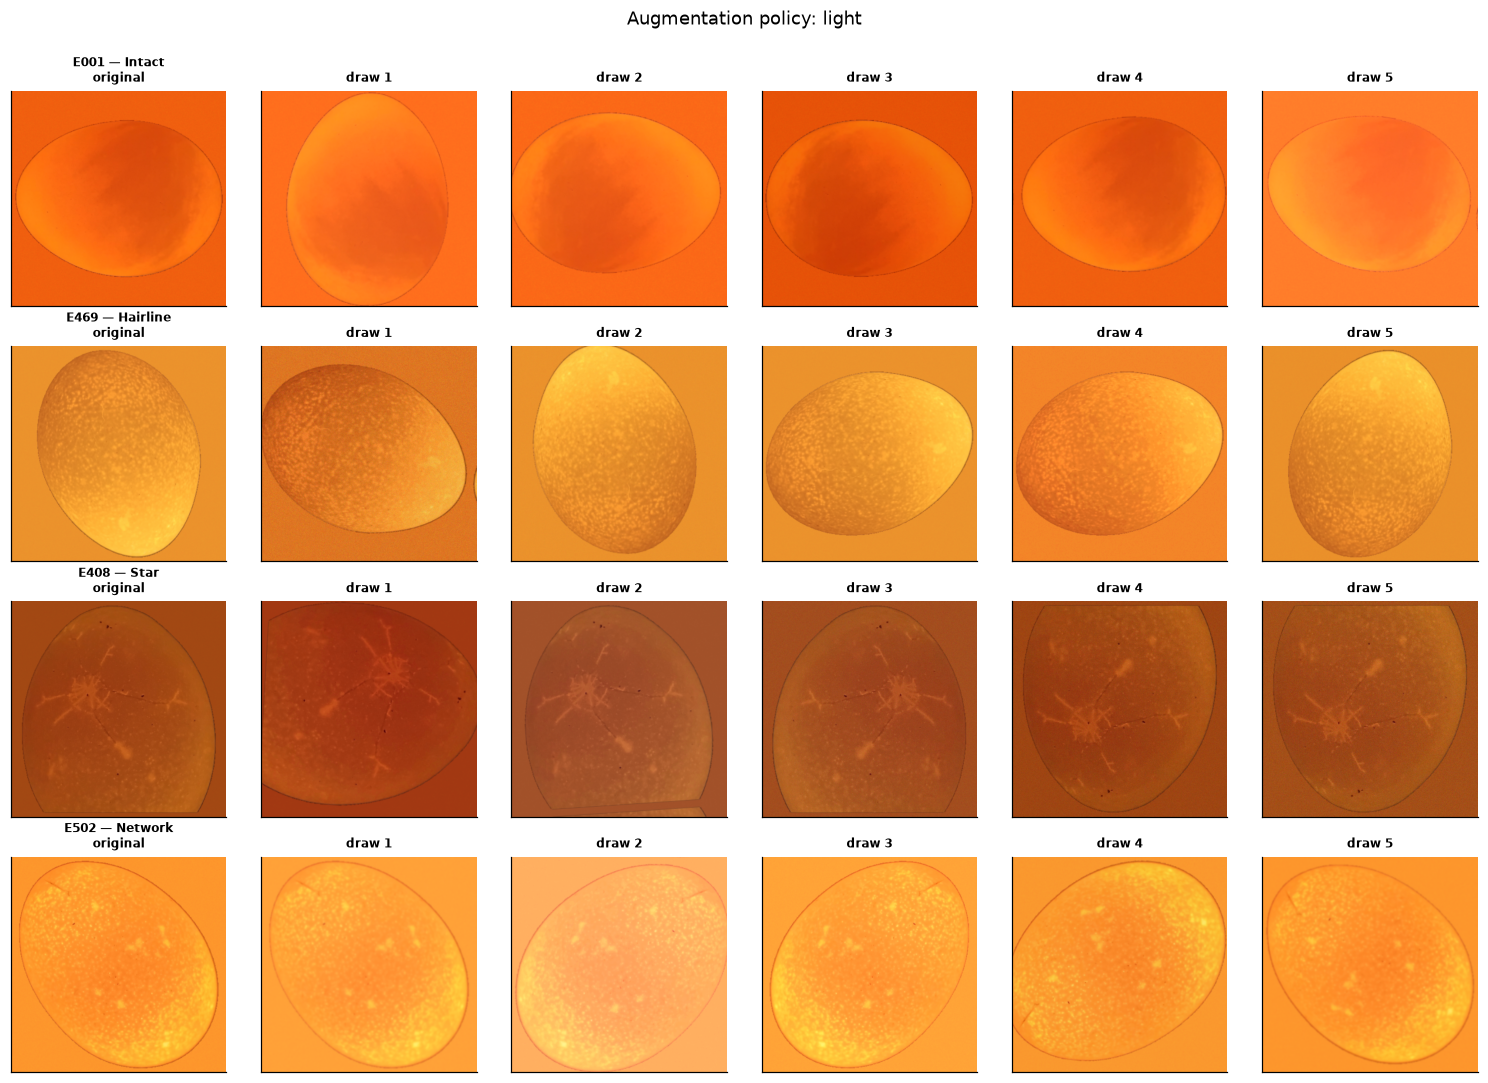

  [figure] 02_policy_grid_medium.png


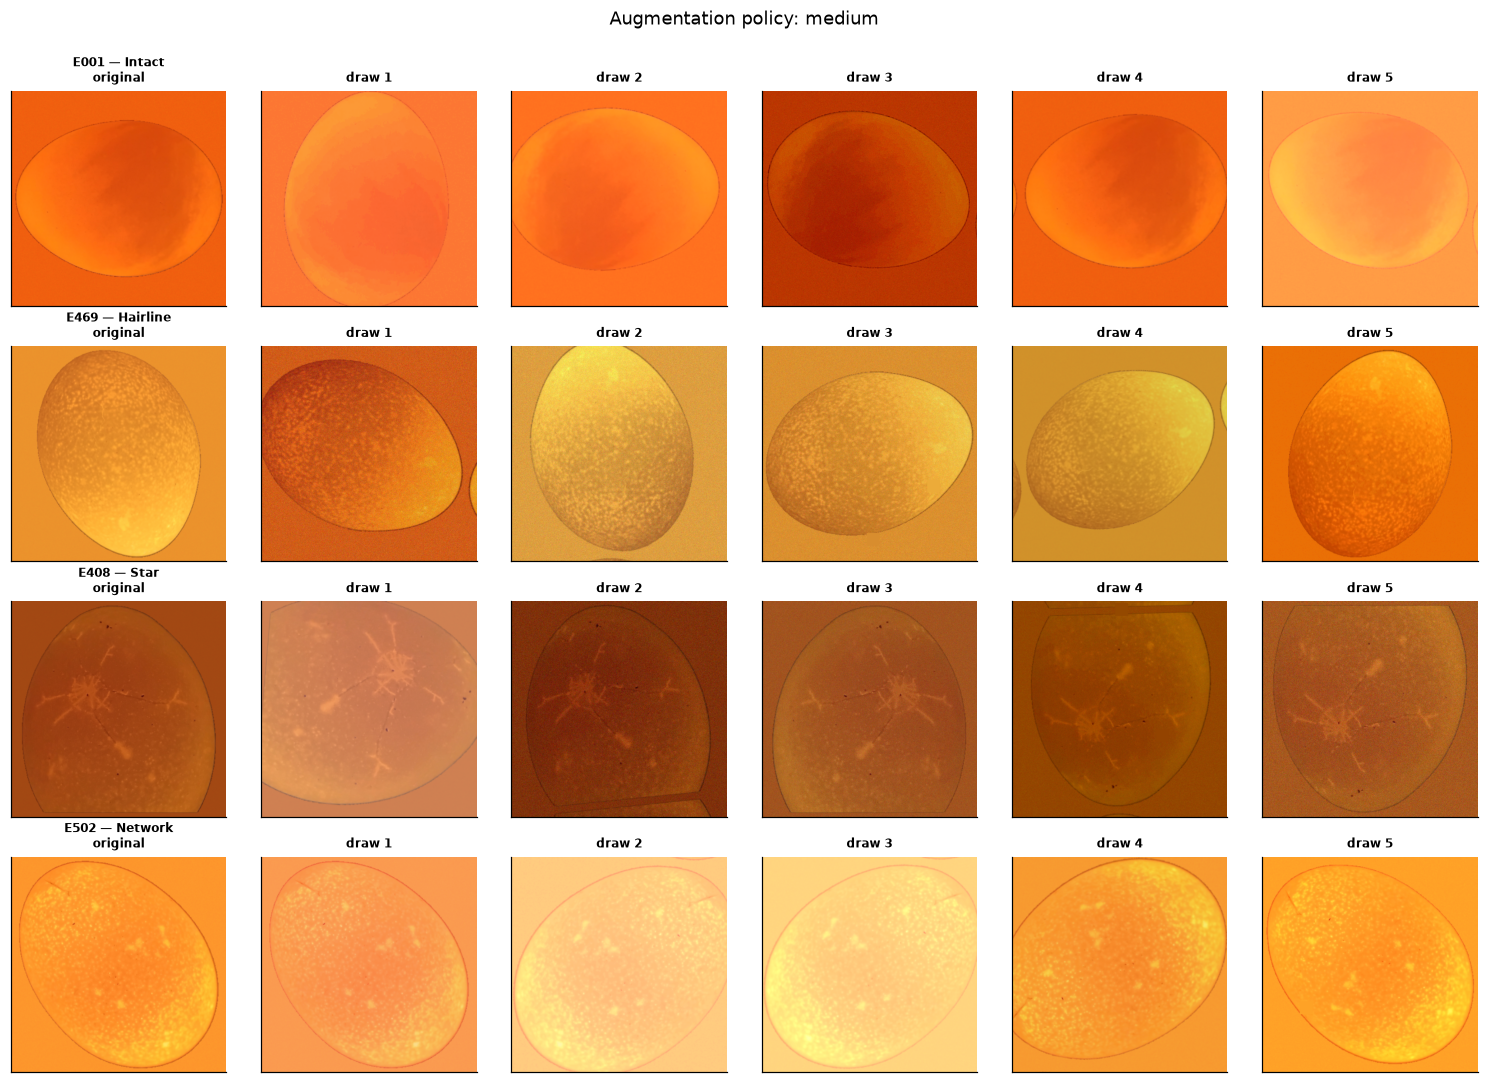

  [figure] 03_policy_grid_heavy.png


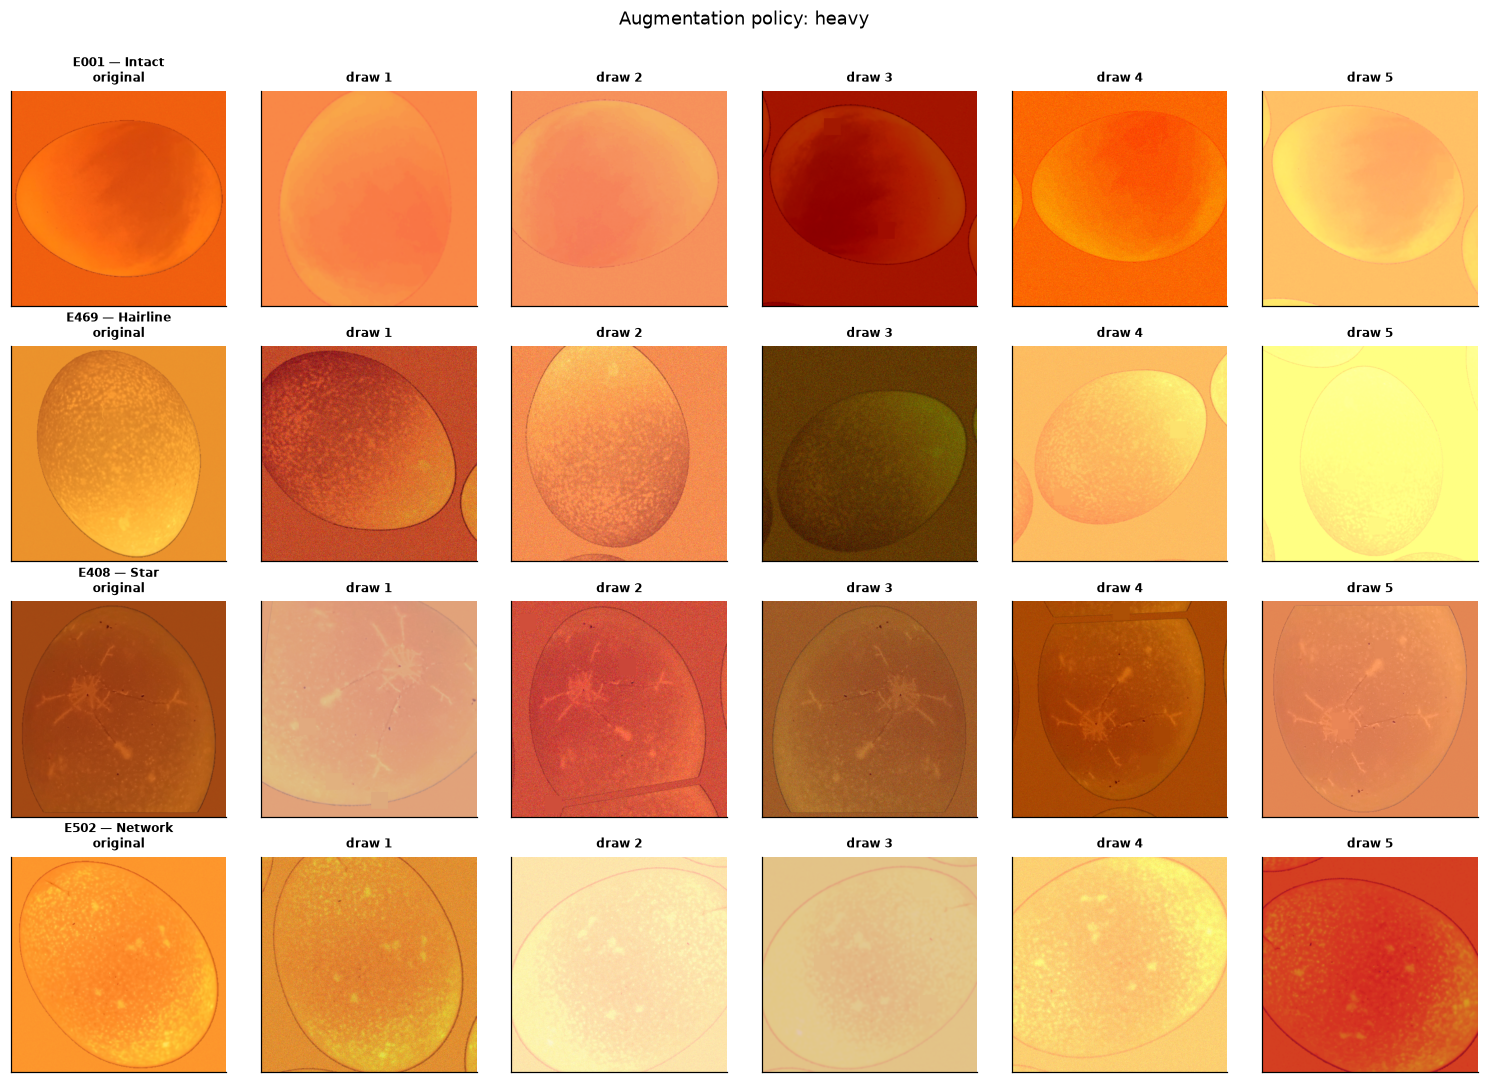

In [4]:
show_ids = []
for cls in CFG.LABEL4:
    s = dev[dev["label4"].eq(cls)]
    if len(s):
        # pick the egg with the median crack area so the example is typical, not extreme
        key = "poly_area_pct" if cls != "Intact" and "poly_area_pct" in s else None
        pick = (s.iloc[(s[key] - s[key].median()).abs().argsort().iloc[0]] if key else s.iloc[0])
        show_ids.append(pick)

for pol in ["light", "medium", "heavy"]:
    n_cols = 6
    fig, axes = plt.subplots(len(show_ids), n_cols, figsize=(2.3 * n_cols, 2.45 * len(show_ids)))
    for r, pick in enumerate(show_ids):
        base = resize_to_train(np.asarray(cache[int(pick["cache_row"])]))
        m = resize_to_train(crack_mask(pick["crack_region"], CACHE_SIDE)[..., None].repeat(3, 2))[..., 0]
        axes[r, 0].imshow(base)
        axes[r, 0].set_title(f"{pick['egg_id']} — {pick['label4']}\noriginal", fontsize=8)
        for c in range(1, n_cols):
            aug = EggAugment(pol, seed=1000 * r + c)
            im, mk = aug(base.copy(), m.copy())
            axes[r, c].imshow(im)
            axes[r, c].set_title(f"draw {c}", fontsize=8)
        for c in range(n_cols):
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
    fig.suptitle(f"Augmentation policy: {pol}", y=1.0, fontsize=12)
    fig.tight_layout()
    savefig(fig, f"policy_grid_{pol}", f"Independent draws from the '{pol}' augmentation policy")
    plt.show()

---
## 2. Does augmentation destroy crack evidence?

An augmentation policy that neutralises the shortcut by also erasing the crack is useless. Two
things are measured for every cracked development egg and every policy.

**Geometric retention** — the proportion of annotated crack area still inside the frame after the
geometric transforms, corrected for the scale factor so that zooming in is not mistaken for loss.
The augmenter records its own affine parameters, so this is exact rather than approximate.

**Crack contrast retention** — the ratio of crack-to-shell intensity contrast after augmentation to
before. This catches what geometry cannot: a blur or a brightness crush that leaves the crack in
frame but invisible. Hairline cracks are thin and low-contrast, so this is the measure that matters
for the minority of eggs the model will find hardest.

In [5]:
cracked = dev[dev["crack_region"].notna() & dev["crack_region"].astype(str).str.strip().ne("")]
print(f"auditing {len(cracked)} cracked development eggs x {len(POLICY_NAMES)} policies "
      f"x {N_AUG_SAMPLES} draws")

def crack_contrast(img, m):
    """Mean intensity difference between the annotated crack band and the surrounding shell."""
    if m.sum() < 10:
        return np.nan
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    k = max(3, int(0.03 * g.shape[0]) | 1)
    ring = cv2.dilate(m, np.ones((k, k), np.uint8)) - m
    if ring.sum() < 10:
        return np.nan
    return float(abs(g[m.astype(bool)].mean() - g[ring.astype(bool)].mean()))

def audit_egg(row, policy, n=N_AUG_SAMPLES):
    base = resize_to_train(np.asarray(cache[int(row["cache_row"])]))
    m0 = crack_mask(row["crack_region"], CACHE_SIDE)
    m0 = cv2.resize(m0, (TRAIN_SIDE, TRAIN_SIDE), interpolation=cv2.INTER_NEAREST)
    if m0.sum() < 10:
        return None
    c0 = crack_contrast(base, m0)
    keeps, contrasts = [], []
    for j in range(n):
        aug = EggAugment(policy, seed=hash((row["egg_id"], policy, j)) % (2**31))
        im, mk = aug(base.copy(), m0.copy())
        sc = aug.last_params.get("scale", 1.0)
        expected = m0.sum() * sc ** 2
        keeps.append(float(mk.sum()) / max(expected, 1.0))
        c1 = crack_contrast(im, mk)
        contrasts.append(c1 / c0 if (c0 and c0 > 0 and not np.isnan(c1)) else np.nan)
    return {"egg_id": row["egg_id"], "label4": str(row["label4"]), "policy": policy,
            "geom_retention": float(np.mean(keeps)),
            "geom_retention_min": float(np.min(keeps)),
            "contrast_retention": float(np.nanmean(contrasts))}

jobs = [(r, p) for p in POLICY_NAMES for _, r in cracked.iterrows()]
res = Parallel(n_jobs=N_JOBS, verbose=1)(delayed(audit_egg)(r, p) for r, p in jobs)
aud = pd.DataFrame([r for r in res if r])
aud["label4"] = pd.Categorical(aud["label4"], categories=CFG.LABEL4, ordered=True)

auditing 284 cracked development eggs x 5 policies x 3 draws


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    4.2s
[Parallel(n_jobs=-1)]: Done 536 tasks      | elapsed:    8.3s
[Parallel(n_jobs=-1)]: Done 1122 tasks      | elapsed:   24.2s
[Parallel(n_jobs=-1)]: Done 1420 out of 1420 | elapsed:   35.1s finished


  [table ] t02_crack_preservation.csv  (5, 7)
                  n  geom_median  geom_p05  pct_geom_above_95  contrast_median  contrast_p05  pct_contrast_above_70
policy                                                                                                             
none            284          1.0     1.000              100.0            1.000         1.000                  100.0
geometric_only  284          1.0     0.998              100.0            0.999         0.812                   97.5
light           284          1.0     0.998              100.0            0.985         0.716                   95.4
medium          284          1.0     0.998              100.0            0.934         0.607                   90.1
heavy           284          1.0     0.999              100.0            0.823         0.420                   70.1
  [table ] t03_contrast_retention_by_class.csv  (5, 3)

crack contrast retention by class (hairline is the fragile one):
label4          Hairl

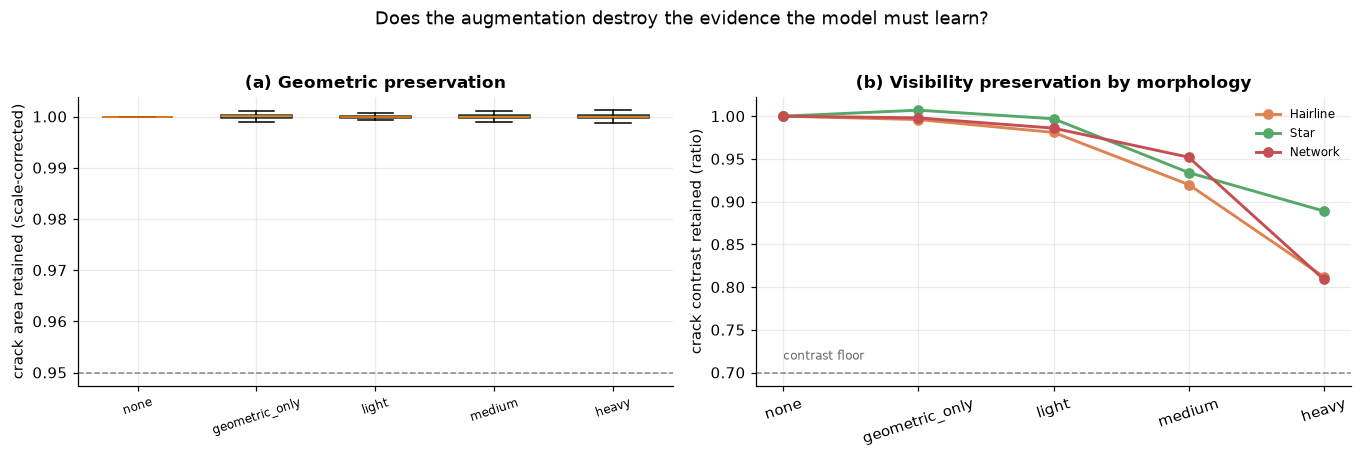

In [6]:
pres = (aud.groupby("policy", observed=True)
          .agg(n=("egg_id", "size"),
               geom_median=("geom_retention", "median"),
               geom_p05=("geom_retention", lambda s: s.quantile(0.05)),
               pct_geom_above_95=("geom_retention", lambda s: round(100 * (s >= 0.95).mean(), 1)),
               contrast_median=("contrast_retention", "median"),
               contrast_p05=("contrast_retention", lambda s: s.quantile(0.05)),
               pct_contrast_above_70=("contrast_retention",
                                      lambda s: round(100 * (s >= 0.70).mean(), 1)))
          .reindex(POLICY_NAMES).round(3))
savetable(pres, "t02_crack_preservation",
          "Annotated crack area and crack contrast retained under each augmentation policy")
S["crack_preservation"] = pres.reset_index().to_dict("records")
print(pres.to_string())

by_cls = (aud.groupby(["policy", "label4"], observed=True)["contrast_retention"]
            .median().unstack().reindex(POLICY_NAMES).round(3))
savetable(by_cls, "t03_contrast_retention_by_class",
          "Median crack-contrast retention by morphology class and policy")
print("\ncrack contrast retention by class (hairline is the fragile one):")
print(by_cls.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
ax = axes[0]
data = [aud.loc[aud["policy"].eq(p), "geom_retention"].dropna().values for p in POLICY_NAMES]
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
for b in bp["boxes"]:
    b.set_facecolor("#55A868"); b.set_alpha(0.8)
ax.set_xticks(range(1, len(POLICY_NAMES) + 1)); ax.set_xticklabels(POLICY_NAMES, rotation=18, fontsize=8)
ax.axhline(0.95, ls="--", color="#888", lw=1)
ax.set_ylabel("crack area retained (scale-corrected)")
ax.set_title("(a) Geometric preservation")

ax = axes[1]
for cls in CFG.PATTERNS:
    v = [by_cls.loc[p, cls] if cls in by_cls.columns else np.nan for p in POLICY_NAMES]
    ax.plot(POLICY_NAMES, v, "o-", color=CFG.PALETTE[cls], label=cls, lw=1.9)
ax.axhline(0.70, ls="--", color="#888", lw=1)
ax.text(0, 0.715, "contrast floor", fontsize=8, color="#666")
ax.set_ylabel("crack contrast retained (ratio)")
ax.set_title("(b) Visibility preservation by morphology")
ax.legend(fontsize=8); ax.tick_params(axis="x", labelrotation=18)
fig.suptitle("Does the augmentation destroy the evidence the model must learn?", y=1.03, fontsize=12)
fig.tight_layout()
savefig(fig, "crack_preservation", "Crack area and contrast retained under each augmentation policy")
plt.show()

---
## 3. Does augmentation neutralise the residual shortcut?

This is the section that justifies the policy choice rather than asserting it. For each policy,
every development egg is augmented `N_AUG_SAMPLES` times, the same capture statistics used in
notebooks 01b and 02 are recomputed from the augmented images after standardisation, and the probe
is run again.

The logic is that a network trained under a policy sees that distribution of images. If capture
statistics no longer separate the classes in the augmented distribution, the shortcut is no longer
available to be learned. A policy that drives this number towards the majority baseline while
keeping crack contrast high is the one to adopt.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import f1_score

POST_FEATS = ["mean_lum", "std_lum", "p01_lum", "p99_lum", "frac_clipped_hi", "frac_clipped_lo",
              "lap_var", "mean_R", "mean_G", "mean_B", "rb_ratio"]

def aug_stats(row, policy, n=N_AUG_SAMPLES):
    """Capture statistics of the augmented, standardised image, averaged over draws."""
    base = resize_to_train(np.asarray(cache[int(row["cache_row"])]))
    acc = []
    for j in range(n):
        aug = EggAugment(policy, seed=hash((row["egg_id"], policy, "s", j)) % (2**31))
        im, _ = aug(base.copy(), None)
        g8 = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        f = standardise(im)
        g = f.mean(axis=2)
        lap = cv2.Laplacian(g.astype(np.float32), cv2.CV_32F)
        acc.append([g.mean(), g.std(), np.percentile(g, 1), np.percentile(g, 99),
                    (g8 >= 250).mean(), (g8 <= 8).mean(), lap.var(),
                    f[:, :, 0].mean(), f[:, :, 1].mean(), f[:, :, 2].mean(),
                    (f[:, :, 0].mean() + 1e-6) / (f[:, :, 2].mean() + 1e-6)])
    return np.asarray(acc).mean(axis=0)

y4 = dev["label4"].astype(str).to_numpy()
y2 = dev["is_cracked"].to_numpy()
groups = dev["capture_block"].to_numpy()

def probe(X, y, grouped=False):
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                         random_state=CFG.RANDOM_SEED)
    cv = (GroupKFold(n_splits=len(np.unique(groups))) if grouped
          else StratifiedKFold(5, shuffle=True, random_state=CFG.RANDOM_SEED))
    yp = cross_val_predict(clf, X, y, cv=cv, groups=groups if grouped else None)
    return round(float(f1_score(y, yp, average="macro")), 3)

rows = []
for pol in POLICY_NAMES:
    t0 = time.time()
    X = np.vstack(Parallel(n_jobs=N_JOBS)(
        delayed(aug_stats)(r, pol) for _, r in dev.iterrows()))
    rows.append({"policy": pol,
                 "4-class (random)": probe(X, y4),
                 "4-class (session-grouped)": probe(X, y4, True),
                 "binary (random)": probe(X, y2),
                 "binary (session-grouped)": probe(X, y2, True)})
    print(f"  {pol:<15s} done in {time.time() - t0:.0f}s -> {rows[-1]}")

leak = pd.DataFrame(rows).set_index("policy")
base4 = round(float(f1_score(y4, np.full_like(y4, "Intact"), average="macro")), 3)
base2 = round(float(f1_score(y2, np.zeros_like(y2), average="macro")), 3)
leak.loc["majority baseline"] = [base4, np.nan, base2, np.nan]
savetable(leak, "t04_leak_under_augmentation",
          "Metadata-only classification of augmented images under each policy")
S["leak_under_augmentation"] = leak.reset_index().to_dict("records")
S["baselines"] = {"four_class": base4, "binary": base2}
print(leak.to_string())

  none            done in 47s -> {'policy': 'none', '4-class (random)': 0.361, '4-class (session-grouped)': 0.292, 'binary (random)': 0.654, 'binary (session-grouped)': 0.621}
  geometric_only  done in 46s -> {'policy': 'geometric_only', '4-class (random)': 0.387, '4-class (session-grouped)': 0.312, 'binary (random)': 0.594, 'binary (session-grouped)': 0.566}
  light           done in 46s -> {'policy': 'light', '4-class (random)': 0.349, '4-class (session-grouped)': 0.292, 'binary (random)': 0.629, 'binary (session-grouped)': 0.594}
  medium          done in 69s -> {'policy': 'medium', '4-class (random)': 0.296, '4-class (session-grouped)': 0.287, 'binary (random)': 0.602, 'binary (session-grouped)': 0.564}
  heavy           done in 81s -> {'policy': 'heavy', '4-class (random)': 0.287, '4-class (session-grouped)': 0.285, 'binary (random)': 0.547, 'binary (session-grouped)': 0.534}
  [table ] t04_leak_under_augmentation.csv  (6, 4)
                   4-class (random)  4-class (session-g

  [figure] 05_leak_under_augmentation.png


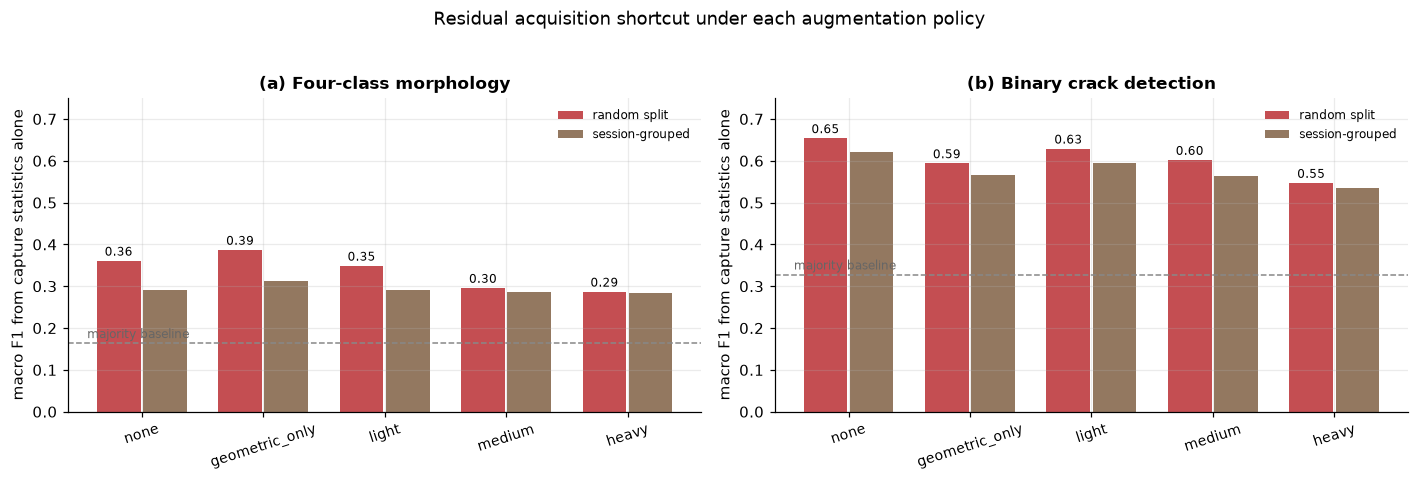

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(POLICY_NAMES))
for ax, (c1, c2, title, base) in zip(axes, [
        ("4-class (random)", "4-class (session-grouped)", "(a) Four-class morphology", base4),
        ("binary (random)", "binary (session-grouped)", "(b) Binary crack detection", base2)]):
    ax.bar(x - 0.19, [leak.loc[p, c1] for p in POLICY_NAMES], 0.36, label="random split",
           color="#C44E52")
    ax.bar(x + 0.19, [leak.loc[p, c2] for p in POLICY_NAMES], 0.36, label="session-grouped",
           color="#937860")
    ax.axhline(base, ls="--", color="#888", lw=1)
    ax.text(-0.45, base + 0.012, "majority baseline", fontsize=8, color="#666")
    for xi, p in zip(x - 0.19, POLICY_NAMES):
        ax.text(xi, leak.loc[p, c1] + 0.012, f"{leak.loc[p, c1]:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(POLICY_NAMES, rotation=18, fontsize=9)
    ax.set_ylabel("macro F1 from capture statistics alone"); ax.set_title(title)
    ax.legend(fontsize=8); ax.set_ylim(0, 0.75)
fig.suptitle("Residual acquisition shortcut under each augmentation policy", y=1.03, fontsize=12)
fig.tight_layout()
savefig(fig, "leak_under_augmentation",
        "Metadata-only classification of augmented images, by augmentation policy")
plt.show()

  [figure] 06_augmentation_tradeoff.png


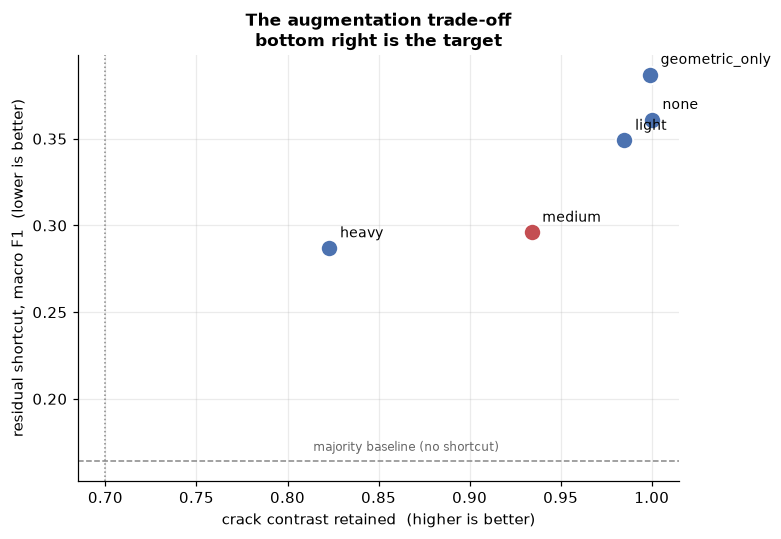

In [9]:
# --- the trade-off, on one pair of axes ----------------------------------
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for pol in POLICY_NAMES:
    xx = pres.loc[pol, "contrast_median"]
    yy = leak.loc[pol, "4-class (random)"]
    ax.scatter(xx, yy, s=130, zorder=3,
               color="#4C72B0" if pol != "medium" else "#C44E52", edgecolor="white", linewidth=1.3)
    ax.annotate(pol, (xx, yy), xytext=(7, 7), textcoords="offset points", fontsize=9)
ax.axhline(base4, ls="--", color="#888", lw=1)
ax.text(ax.get_xlim()[0], base4 + 0.006, "majority baseline (no shortcut)", fontsize=8, color="#666")
ax.axvline(0.70, ls=":", color="#888", lw=1)
ax.set_xlabel("crack contrast retained  (higher is better)")
ax.set_ylabel("residual shortcut, macro F1  (lower is better)")
ax.set_title("The augmentation trade-off\nbottom right is the target")
fig.tight_layout()
savefig(fig, "augmentation_tradeoff",
        "Trade-off between neutralising the acquisition shortcut and preserving crack visibility")
plt.show()

---
## 4. Throughput

The RTX 3050 has 6 GB, so training will run at modest batch sizes and the GPU must not be left
waiting on the CPU. This measures how many augmented images per second the pipeline produces,
against roughly what the GPU will consume.

In [10]:
def bench(policy, n=120, side=TRAIN_SIDE):
    idx = np.random.default_rng(0).integers(0, len(dev), n)
    base = [resize_to_train(np.asarray(cache[int(dev.iloc[i]["cache_row"])]), side) for i in idx]
    aug = EggAugment(policy, seed=0)
    t0 = time.time()
    for im in base:
        a, _ = aug(im.copy(), None)
        _ = standardise(a)
    return n / (time.time() - t0)

cores = os.cpu_count() or 4
rows = []
for pol in POLICY_NAMES:
    per_core = bench(pol)
    rows.append({"policy": pol, "img_per_s_single_core": round(per_core, 1),
                 "est_img_per_s_8_workers": round(per_core * 8, 0)})
tp = pd.DataFrame(rows).set_index("policy")
savetable(tp, "t05_throughput", "Augmentation throughput per policy")
S["throughput"] = tp.reset_index().to_dict("records")
print(f"detected {cores} logical cores\n")
print(tp.to_string())
print("\nAs a rough target, an EfficientNet-B0 at 384 px on a 6 GB RTX 3050 consumes roughly")
print("80-150 images/s during training. Any policy at or above that with 8 DataLoader workers")
print("keeps the GPU saturated; set num_workers=8, persistent_workers=True, pin_memory=True.")

  [table ] t05_throughput.csv  (5, 2)
detected 8 logical cores

                img_per_s_single_core  est_img_per_s_8_workers
policy                                                        
none                             90.0                    720.0
geometric_only                  103.2                    826.0
light                            48.0                    384.0
medium                           26.3                    210.0
heavy                            24.4                    195.0

As a rough target, an EfficientNet-B0 at 384 px on a 6 GB RTX 3050 consumes roughly
80-150 images/s during training. Any policy at or above that with 8 DataLoader workers
keeps the GPU saturated; set num_workers=8, persistent_workers=True, pin_memory=True.


---
## 5. Decision

In [11]:
# Selection rule.
#
# An earlier version of this rule tested the MEDIAN crack contrast, which was a mistake: the median
# hides exactly the cases that matter. The policies damage crack visibility in the tail, and the
# tail is where the minority classes and the thin hairline cracks live. The rule therefore tests
# the 5th percentile and the proportion of cracks clearing the floor, and additionally requires
# that a more aggressive policy actually buy a worthwhile reduction in the shortcut.
CONTRAST_FLOOR = 0.70      # below this, a thin hairline crack starts to disappear
MIN_PCT_ABOVE_FLOOR = 85.0 # at most 15% of cracks may fall below it
MIN_P05_CONTRAST = 0.60    # the worst 5% must still retain 60% of their contrast
GEOM_FLOOR = 0.95
MIN_LEAK_GAIN = 0.02       # a harsher policy must reduce the shortcut by at least this much

elig = [p for p in POLICY_NAMES
        if p != "none"
        and pres.loc[p, "pct_contrast_above_70"] >= MIN_PCT_ABOVE_FLOOR
        and pres.loc[p, "contrast_p05"] >= MIN_P05_CONTRAST
        and pres.loc[p, "geom_median"] >= GEOM_FLOOR]

print("policy screen:")
for p in POLICY_NAMES:
    if p == "none":
        continue
    ok = p in elig
    print(f"   {p:<16s} pct_above_floor={pres.loc[p, 'pct_contrast_above_70']:>6}  "
          f"p05={pres.loc[p, 'contrast_p05']:>6}  leak4={leak.loc[p, '4-class (random)']:>6}  "
          f"{'ELIGIBLE' if ok else 'rejected: damages too many cracks'}")

if not elig:
    chosen, shortlist = "light", ["light"]
else:
    # Among eligible policies, start from the mildest and step up only where the extra
    # aggression buys a real reduction in the shortcut.
    order = [p for p in POLICY_NAMES if p in elig]
    chosen = order[0]
    for p in order[1:]:
        gain = max(leak.loc[chosen, "4-class (random)"] - leak.loc[p, "4-class (random)"],
                   leak.loc[chosen, "binary (random)"] - leak.loc[p, "binary (random)"])
        if gain >= MIN_LEAK_GAIN:
            chosen = p
    # Any eligible policy within MIN_LEAK_GAIN of the choice is not distinguishable by this
    # probe on a single cross-validation run. Rather than pretend otherwise, the shortlist is
    # carried into notebook 05 and resolved on actual model performance.
    shortlist = [p for p in order
                 if abs(leak.loc[p, "4-class (random)"] - leak.loc[chosen, "4-class (random)"])
                 < MIN_LEAK_GAIN]
    if chosen not in shortlist:
        shortlist.append(chosen)

print(f"\nADOPTED POLICY: {chosen}")
print(f"  residual shortcut 4-class : {leak.loc[chosen, '4-class (random)']} "
      f"(no augmentation: {leak.loc['none', '4-class (random)']}; baseline {base4})")
print(f"  residual shortcut binary  : {leak.loc[chosen, 'binary (random)']} "
      f"(no augmentation: {leak.loc['none', 'binary (random)']}; baseline {base2})")
print(f"  crack area retained       : {pres.loc[chosen, 'geom_median']}")
print(f"  crack contrast, median    : {pres.loc[chosen, 'contrast_median']}")
print(f"  crack contrast, 5th pct   : {pres.loc[chosen, 'contrast_p05']}")
print(f"  cracks below floor        : {100 - pres.loc[chosen, 'pct_contrast_above_70']:.1f}%")
if len(shortlist) > 1:
    print(f"\n  NOTE: {shortlist} are not separable by this probe on a single CV run.")
    print(f"  All of them are carried into notebook 05 as a training-time ablation and the")
    print(f"  choice is settled on model macro F1 rather than on this proxy.")

S["chosen_policy"] = chosen
S["shortlist"] = shortlist
S["chosen_metrics"] = {
    "contrast_p05": float(pres.loc[chosen, "contrast_p05"]),
    "pct_contrast_above_floor": float(pres.loc[chosen, "pct_contrast_above_70"]),
    "leak_4class": float(leak.loc[chosen, "4-class (random)"]),
    "leak_4class_grouped": float(leak.loc[chosen, "4-class (session-grouped)"]),
    "leak_binary": float(leak.loc[chosen, "binary (random)"]),
    "geom_retention": float(pres.loc[chosen, "geom_median"]),
    "contrast_retention": float(pres.loc[chosen, "contrast_median"]),
}
(PROC / "augmentation_policy.json").write_text(json.dumps(
    {"policy": chosen, "shortlist": shortlist, "train_side": TRAIN_SIDE,
     "cache_variant": CACHE_VARIANT,
     "parameters": {p: POLICIES[p].describe() for p in shortlist}}, indent=2))
print(f"\nwrote {PROC / 'augmentation_policy.json'} — notebooks 05 and 07 read this")

policy screen:
   geometric_only   pct_above_floor=  97.5  p05= 0.812  leak4= 0.387  ELIGIBLE
   light            pct_above_floor=  95.4  p05= 0.716  leak4= 0.349  ELIGIBLE
   medium           pct_above_floor=  90.1  p05= 0.607  leak4= 0.296  ELIGIBLE
   heavy            pct_above_floor=  70.1  p05=  0.42  leak4= 0.287  rejected: damages too many cracks

ADOPTED POLICY: medium
  residual shortcut 4-class : 0.296 (no augmentation: 0.361; baseline 0.164)
  residual shortcut binary  : 0.602 (no augmentation: 0.654; baseline 0.328)
  crack area retained       : 1.0
  crack contrast, median    : 0.934
  crack contrast, 5th pct   : 0.607
  cracks below floor        : 9.9%

wrote D:\Eggshell-Diagnostic-Research\Artefact\data\processed\augmentation_policy.json — notebooks 05 and 07 read this


In [12]:
S["figures"], S["tables"] = FIGS, TABS
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "augmentation_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 03 DIGEST -- AUGMENTATION POLICY", "=" * 70,
     f"generated: {S['generated_at']}", f"training resolution: {TRAIN_SIDE}px", "",
     "RESIDUAL SHORTCUT UNDER EACH POLICY (macro F1 from capture statistics alone)"]
for r in S["leak_under_augmentation"]:
    L.append(f"   {r['policy']:<18s} 4cls={r['4-class (random)']:<6} "
             f"4cls_grp={r['4-class (session-grouped)']:<6} bin={r['binary (random)']}")
L += ["", "CRACK EVIDENCE PRESERVED"]
for r in S["crack_preservation"]:
    L.append(f"   {r['policy']:<18s} geom={r['geom_median']:<6} contrast={r['contrast_median']:<6} "
             f"pct_contrast>=0.70={r['pct_contrast_above_70']}")
L += ["", "THROUGHPUT"]
for r in S["throughput"]:
    L.append(f"   {r['policy']:<18s} {r['img_per_s_single_core']} img/s/core  "
             f"~{r['est_img_per_s_8_workers']} img/s with 8 workers")
L += ["", f"ADOPTED POLICY: {S['chosen_policy']}",
      f"   {S['chosen_metrics']}",
      f"   shortlist carried to notebook 05: {S['shortlist']}", "=" * 70]
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

NOTEBOOK 03 DIGEST -- AUGMENTATION POLICY
generated: 2026-10-11T00:01:41
training resolution: 384px

RESIDUAL SHORTCUT UNDER EACH POLICY (macro F1 from capture statistics alone)
   none               4cls=0.361  4cls_grp=0.292  bin=0.654
   geometric_only     4cls=0.387  4cls_grp=0.312  bin=0.594
   light              4cls=0.349  4cls_grp=0.292  bin=0.629
   medium             4cls=0.296  4cls_grp=0.287  bin=0.602
   heavy              4cls=0.287  4cls_grp=0.285  bin=0.547
   majority baseline  4cls=0.164  4cls_grp=nan    bin=0.328

CRACK EVIDENCE PRESERVED
   none               geom=1.0    contrast=1.0    pct_contrast>=0.70=100.0
   geometric_only     geom=1.0    contrast=0.999  pct_contrast>=0.70=97.5
   light              geom=1.0    contrast=0.985  pct_contrast>=0.70=95.4
   medium             geom=1.0    contrast=0.934  pct_contrast>=0.70=90.1
   heavy              geom=1.0    contrast=0.823  pct_contrast>=0.70=70.1

THROUGHPUT
   none               90.0 img/s/core  ~720.0 img/s w